# Derivative-of-Gaussian Kernel Analysis

This notebook implements and compares different versions of the Derivative-of-Gaussian (DoG) kernel for discrete-time derivative estimation, based on the formulas from `root.tex`.

## Import Libraries

In [23]:
import numpy as np
import matplotlib.pyplot as plt


font_increase = 3

# Enable LaTeX rendering for matplotlib
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 12 +font_increase  # Default font size
plt.rcParams['axes.labelsize'] = 12 +font_increase  # Axis labels
plt.rcParams['axes.titlesize'] = 14 +font_increase  # Title
plt.rcParams['xtick.labelsize'] = 10 +font_increase  # X-axis ticks
plt.rcParams['ytick.labelsize'] = 10 +font_increase  # Y-axis ticks
plt.rcParams['legend.fontsize'] = 11 +font_increase  # Legend

## Input Parameters

Set the cutoff frequency and sampling frequency. All other parameters are derived from these.

In [24]:
f_cut = 5  # Cutoff frequency in Hz
f_s = 200  # Sampling frequency in Hz
freq = 1  # Hz (frequency of sine wave for testing)
noise_fraction = 0.0 # 0.02 -> +-2% of signal amplitude added noise
noise_base = 0.05  # Base noise level

## Calculate Derived Parameters

From the paper formulas:
- $\sigma = \frac{1}{2\pi f_{\text{cut}}}$
- $N = 2K+1 = \lceil 6\sigma f_s \rceil$

In [25]:
# sigma = 1 / (2 * pi * f_cut)
sigma = 1 / (2 * np.pi * f_cut)

# N = ceil(6 * sigma * f_s)
N = int(np.ceil(6 * sigma * f_s))

# Ensure N is odd (2K+1 form)
if N % 2 == 0:
    N += 1

K = (N - 1) // 2  # Half-window size
dt = 1 / f_s  # Time step

print(f"Input Parameters:")
print(f"  f_cut = {f_cut:.2f} Hz")
print(f"  f_s = {f_s} Hz")
print(f"\nDerived Parameters:")
print(f"  sigma = {sigma:.6f}")
print(f"  N = {N} (window size)")
print(f"  K = {K} (half-window)")
print(f"  delay = {K*dt} s")

Input Parameters:
  f_cut = 5.00 Hz
  f_s = 200 Hz

Derived Parameters:
  sigma = 0.031831
  N = 39 (window size)
  K = 19 (half-window)
  delay = 0.095 s


## Non-Causal Kernel

Symmetric kernel centered at k=0:

$$h[k] = -\frac{t_k}{\sigma^3 \sqrt{2\pi}} \exp\left(-\frac{t_k^2}{2\sigma^2}\right) \cdot \Delta t$$

where $t_k = k \cdot \Delta t$ for $k \in [-K, K]$

In [26]:
k_noncausal = np.arange(-K, K + 1)  # k in [-K, K]
t_k = k_noncausal * dt

# h[k] = -(t_k / (sigma^3 * sqrt(2*pi))) * exp(-t_k^2 / (2*sigma^2))
# Multiply by dt to account for discrete approximation of the integral
h_noncausal = -(t_k / (sigma**3 * np.sqrt(2 * np.pi))) * np.exp(-t_k**2 / (2 * sigma**2)) * dt

## Causal Kernel Versions

We create multiple versions of the causal kernel to compare their performance:

1. **Truncated + Normalized**: The paper version with mean centering and L2 normalization
2. **Truncated Raw**: Just mean centering, no L2 normalization
3. **Shifted**: The non-causal kernel shifted by K samples (delayed but not truncated)

In [27]:
# First create h_c[k] = h[-k] for k in [0, 2K]
k_causal_raw = np.arange(0, 2*K + 1)  # k in [0, 2K]
t_k_causal_raw = -k_causal_raw * dt  # We use h[-k], so negative time

h_causal_raw = -(t_k_causal_raw / (sigma**3 * np.sqrt(2 * np.pi))) * np.exp(-t_k_causal_raw**2 / (2 * sigma**2)) * dt

# Version 1: Truncated raw (no processing)
h_causal_unnormalized = h_causal_raw.copy()

# Version 2: Shifted non-causal kernel (no truncation)
h_causal_shifted = h_noncausal.copy()

# Version 3: Truncated with mean removal and L2 normalization (paper version)
h_bar = np.mean(h_causal_raw)
h_tilde = h_causal_raw - h_bar
E = np.sqrt(np.sum(h_tilde**2))
h_causal = h_tilde / E

## Plot: Kernel Comparison

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.



Saved kernel comparison plot to kernel_comparison.eps


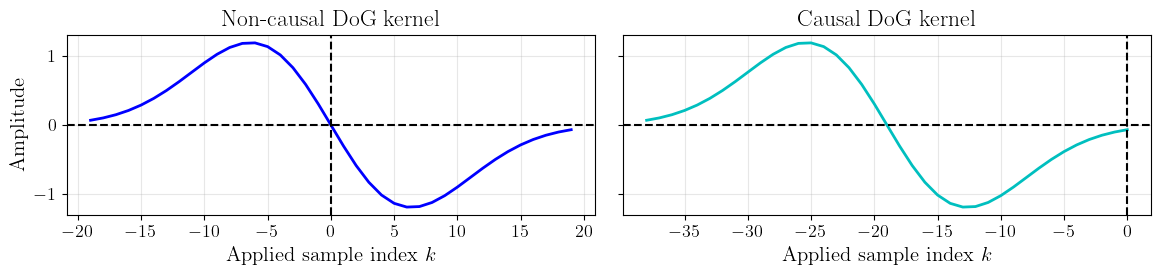

In [28]:
#fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))
fig, (ax1, ax4) = plt.subplots(1, 2, figsize=(12, 3), sharey=True)

# Non-causal kernel
ax1.plot(k_noncausal, h_noncausal, 'b-', linewidth=2)
ax1.axhline(y=0, color='k', linestyle='--', linewidth=1.5)
ax1.axvline(x=0, color='k', linestyle='--', linewidth=1.5)
ax1.grid(True, alpha=0.3)
ax1.set_xlabel('Applied sample index $k$')
ax1.set_ylabel('Amplitude')
ax1.set_title(f'Non-causal DoG kernel')


# # Causal kernel (normalized)
# ax2.plot(-k_causal_raw, h_causal, 'r-', linewidth=2)
# ax2.axhline(y=0, color='k', linestyle='--', linewidth=0.5)
# ax2.grid(True, alpha=0.3)
# ax2.set_xlabel('Sample index $k$')
# ax2.set_ylabel('Amplitude')
# ax2.set_title('Causal: Truncated, Mean-Removed, Normalized')


# # Causal kernel (raw, no normalization)
# ax3.plot(-k_causal_raw, h_causal_unnormalized, 'm-', linewidth=2)
# ax3.axhline(y=0, color='k', linestyle='--', linewidth=0.5)
# ax3.grid(True, alpha=0.3)
# ax3.set_xlabel('Sample index $k$')
# ax3.set_ylabel('Amplitude')
# ax3.set_title('Causal: Truncated Only (No Processing)')


# Causal kernel (shifted, not truncated)
ax4.plot(-(k_noncausal + K), -h_causal_shifted, 'c-', linewidth=2)
ax4.axhline(y=0, color='k', linestyle='--', linewidth=1.5)
ax4.axvline(x=0, color='k', linestyle='--', linewidth=1.5)
ax4.grid(True, alpha=0.3)
ax4.set_xlabel('Applied sample index $k$')
#ax4.set_ylabel('Amplitude')
ax4.set_title('Causal DoG kernel')


plt.tight_layout()
plt.savefig('/home/fabi/catkin_ws/src/ros_imu_calib/pub/img/kernel_comparison.eps', format='eps', dpi=600)
print("\nSaved kernel comparison plot to kernel_comparison.eps")
plt.show()

## Generate Test Signal

Create a sine wave and compute its analytical derivative for comparison.

In [29]:
# Create a clean decaying sine wave sampled at 200 Hz
# x_clean(t) = e^{-t/3} sin(2*pi*f*t)
duration = 7.0  # seconds
t = np.arange(0, duration, dt)
x_clean = np.sin(2 * np.pi * freq * t) * np.exp(-t / 3)

# Add signal-dependent noise (±2% of signal amplitude + base noise 0.01)
np.random.seed(42)  # For reproducibility
noise = (noise_fraction * np.abs(x_clean) + noise_base) * np.random.randn(len(t))
x = x_clean + noise

# Analytical derivative: d/dt[e^{-t/3} sin(2*pi*f*t)]
dx_dt_true = np.exp(-t / 3) * (
    2 * np.pi * freq * np.cos(2 * np.pi * freq * t)
    - (1.0 / 3.0) * np.sin(2 * np.pi * freq * t)
)

## Manual Convolution

Implement the convolution using explicit loops as per the formulas in the paper:

**Non-causal:**
$$\frac{\partial x[n]}{\partial t} = \sum_{k=-K}^{K} h[k] \cdot x[n-k]$$

**Causal:**
$$\frac{\partial x[n]}{\partial t} = \sum_{k=-K}^{K} h[k] \cdot x[n-k-K]$$


In [30]:
"""
Convolution function

parameters:
data: numpy array of shape (N, 4) with first column timestamps, next three columns data to be convolved
kernel: 1D numpy array with convolution kernel (should have odd length)

returns:
numpy array of shape (N, 4) with first column timestamps, next three columns convolved data
"""
def convolve(data, kernel):
    res = np.zeros_like(data)
    K = (len(kernel) - 1) // 2 # floor division
    for n in range(len(data)):
        for k in range(-K, K + 1):
            idx = n - k - K  # Shift by K to make it causal
            if 0 <= idx < len(data):
                res[n] += kernel[k + K] * data[idx]
    return res

# Apply convolutions using the convolve function
dx_dt_noncausal = convolve(x, h_noncausal)
dx_dt_causal = convolve(x, h_causal)
dx_dt_causal_unnorm = convolve(x, h_causal_unnormalized)
dx_dt_causal_shifted = convolve(x, h_causal_shifted)

# Finite differences (central) for comparison
dx_dt_fd = np.gradient(x, dt)

## Plot: Derivative Comparison

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved derivative comparison plot to derivative_comparison.eps


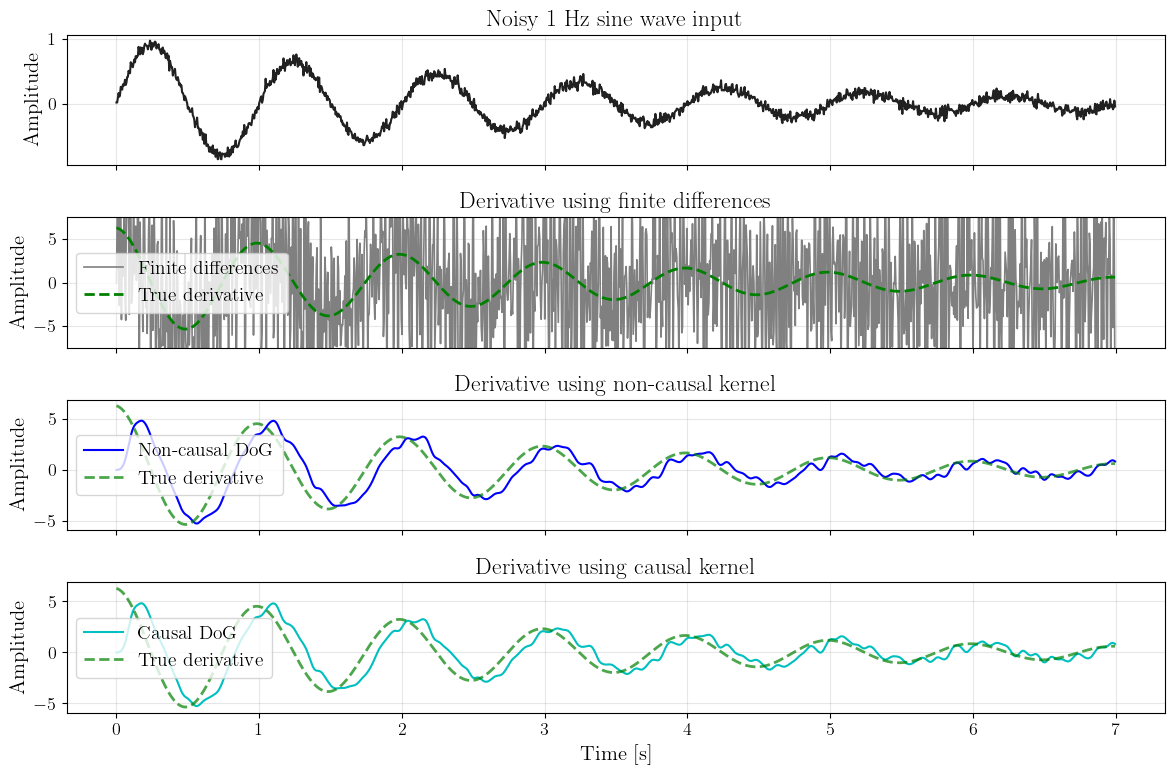

In [31]:
#fig, (ax1, ax2, ax3, ax4, ax5, ax6) = plt.subplots(6, 1, figsize=(12, 14))
fig, (ax1, ax2, ax5, ax6) = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

# Plot 1: Original signal (showing both clean and noisy)
ax1.plot(t, x, color='0.13')
ax1.grid(True, alpha=0.3)
#ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Amplitude')
ax1.set_title('Noisy 1~Hz sine wave input')

# Plot 2: Derivative using finite differences
ax2.plot(t, dx_dt_fd, color='0.5', linewidth=1.2, label='Finite differences')
ax2.plot(t, dx_dt_true, 'g--', linewidth=2, label='True derivative')
ax2.grid(True, alpha=0.3)
ax2.set_ylabel('Amplitude')
ax2.set_ylim([-7.5, 7.5])
ax2.set_title('Derivative using finite differences')
ax2.legend()

# # Plot 3: Derivative using causal kernel
# ax3.plot(t, dx_dt_true, 'g-', linewidth=2, alpha=0.7, label='True derivative (clean signal)')
# ax3.plot(t, dx_dt_causal, 'r--', linewidth=1.5, label='Causal DoG on noisy signal (normalized)')
# ax3.grid(True, alpha=0.3)
# ax3.set_xlabel('Time [s]')
# ax3.set_ylabel('Derivative')
# ax3.set_title('Derivative using Causal Kernel (mean-removed, L2-normalized)')
# ax3.legend()

# # Plot 4: Derivative using unnormalized causal kernel
# ax4.plot(t, dx_dt_true, 'g-', linewidth=2, alpha=0.7, label='True derivative (clean signal)')
# ax4.plot(t, dx_dt_causal_unnorm, 'm--', linewidth=1.5, label='Causal DoG on noisy signal (raw)')
# ax4.grid(True, alpha=0.3)
# ax4.set_xlabel('Time [s]')
# ax4.set_ylabel('Derivative')
# ax4.set_title('Derivative using Causal Kernel (truncated, no processing)')
# ax4.legend()

# Plot 5: Derivative using shifted (non-truncated) causal kernel
ax5.plot(t, dx_dt_noncausal, 'b-', linewidth=1.5, label='Non-causal DoG')
ax5.plot(t, dx_dt_true, 'g--', linewidth=2, alpha=0.7, label='True derivative')
ax5.grid(True, alpha=0.3)
#ax2.set_xlabel('Time [s]')
ax5.set_ylabel('Amplitude')
ax5.set_title('Derivative using non-causal kernel')
ax5.legend()

ax6.plot(t, dx_dt_causal_shifted, 'c-', linewidth=1.5, label='Causal DoG')
ax6.plot(t, dx_dt_true, 'g--', linewidth=2, alpha=0.7, label='True derivative')
ax6.grid(True, alpha=0.3)
ax6.set_xlabel('Time [s]')
ax6.set_ylabel('Amplitude')
ax6.set_title('Derivative using causal kernel')
ax6.legend()

plt.tight_layout()
plt.savefig('/home/fabi/catkin_ws/src/ros_imu_calib/pub/img/derivative_comparison.eps', format='eps', dpi=600)
print("Saved derivative comparison plot to derivative_comparison.eps")
plt.show()

## Phase Fit: Causal Derivative

Fit a cosine to the causal-kernel derivative and compute the phase shift versus the true derivative.

Phase shift (fitted vs true): -34.13 degrees
Time lag (fitted vs true): -0.094816 s


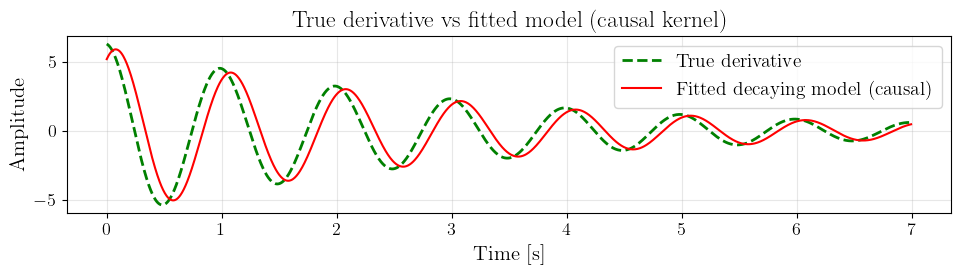

In [32]:
# Fit decaying sinusoid derivative to causal-kernel output and compute phase shift
omega = 2 * np.pi * freq

# Use central portion to avoid edge effects from convolution
start_idx = K
end_idx = len(t) - K if len(t) > 2 * K else len(t)
fit_slice = slice(start_idx, end_idx)

t_fit = t[fit_slice]
y_fit = dx_dt_causal_shifted[fit_slice]

# Linear least squares fit with decaying basis:
# y = e^{-t/3}*(a*cos(ωt) + b*sin(ωt)) + c
exp_decay = np.exp(-t_fit / 3)
X = np.column_stack([
    exp_decay * np.cos(omega * t_fit),
    exp_decay * np.sin(omega * t_fit),
    np.ones_like(t_fit)
])
coef, _, _, _ = np.linalg.lstsq(X, y_fit, rcond=None)
a, b, c = coef

A_fit = np.hypot(a, b)
phi_fit = np.arctan2(-b, a)  # a cos + b sin = A cos(ωt + phi)

# Reference phase from true derivative (same decaying basis)
coef_true, _, _, _ = np.linalg.lstsq(X, dx_dt_true[fit_slice], rcond=None)
a_true, b_true, _ = coef_true
phi_true = np.arctan2(-b_true, a_true)

# Phase shift (wrapped to [-pi, pi])
phase_shift = (phi_fit - phi_true + np.pi) % (2 * np.pi) - np.pi
phase_shift_deg = np.degrees(phase_shift)
phase_shift_time = phase_shift / omega

# Reconstruct fitted model
exp_decay_full = np.exp(-t / 3)
y_fit_model = exp_decay_full * (A_fit * np.cos(omega * t + phi_fit)) + c

# Plot comparison
plt.figure(figsize=(10, 3))
plt.plot(t, dx_dt_true, 'g--', linewidth=2, label='True derivative')
plt.plot(t, y_fit_model, 'r-', linewidth=1.5, label='Fitted decaying model (causal)')
plt.grid(True, alpha=0.3)
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.title('True derivative vs fitted model (causal kernel)')
plt.legend()
plt.tight_layout()

print(f"Phase shift (fitted vs true): {phase_shift_deg:.2f} degrees")
print(f"Time lag (fitted vs true): {phase_shift_time:.6f} s")

## Amplitude- and Phase-Response vs Cutoff Frequency

Sweep $f_{\mathrm{cut}}$ while keeping $f_s$ fixed and compute the phase shift of the causal kernel output relative to the true derivative.

/tmp/ipykernel_5571/2314352479.py:190: RuntimeWarning: divide by zero encountered in log10
  amplitude_ratio_db = 20 * np.log10(amp_ratio)
/tmp/ipykernel_5571/2314352479.py:198: RuntimeWarning: divide by zero encountered in log10
  noise_gain_db = 20 * np.log10(noise_gain)
/tmp/ipykernel_5571/2314352479.py:202: RuntimeWarning: divide by zero encountered in log10
  amplitude_ratio_db = 20 * np.log10(amp_ratio)


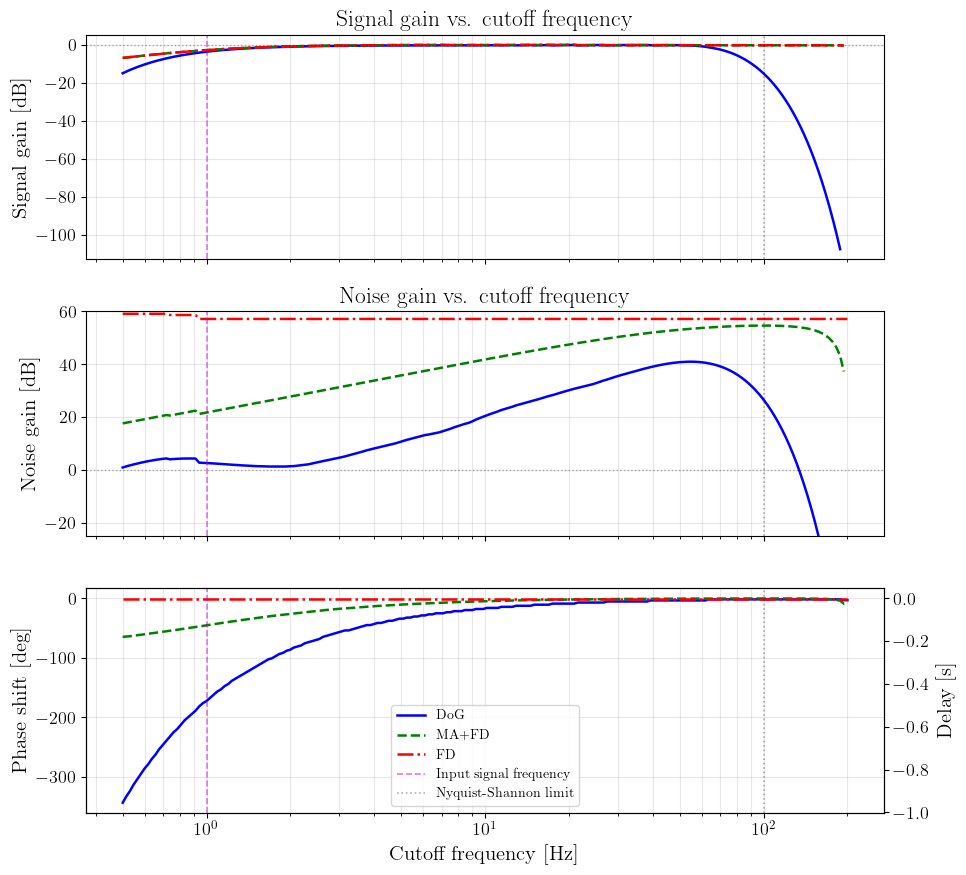

In [42]:
"""
Noise level function

parameters:
data: the data
mode: chose from [median, max, rms] (default median)

returns:
noise level (scalar)
"""
def get_noise_level(data, mode='median'):
    if mode == 'median':
        return np.median(np.abs(data))
    elif mode == 'max':
        return np.max(np.abs(data))
    elif mode == 'rms':
        return np.sqrt(np.sum(data**2))
    else:
        print(f"Mode {mode} not defined. Using median!")
        return np.median(np.abs(data))

def backward_diff(x, dt, order=3):
    """Causal backward finite differences using only past samples."""
    if order == 1:
        return np.r_[0.0, np.diff(x)] / dt
    if order == 2:
        # 2nd-order backward: (3x[n]-4x[n-1]+x[n-2])/(2dt)
        return np.r_[0.0, 0.0, (3*x[2:] - 4*x[1:-1] + x[:-2]) / (2*dt)]
    if order == 3:
        # 3rd-order backward: (11x[n]-18x[n-1]+9x[n-2]-2x[n-3])/(6dt)
        return np.r_[0.0, 0.0, 0.0, (11*x[3:] - 18*x[2:-1] + 9*x[1:-2] - 2*x[:-3]) / (6*dt)]
    raise ValueError('order must be 1, 2, or 3')

def lowpass_filter(x, f_cut, f_sample):
    """Causal 1st-order lowpass using alpha from cutoff/sample frequency."""
    c = np.cos(2 * np.pi * f_cut / f_sample)
    alpha = np.sqrt(c * c - 4 * c + 3) + c - 1
    y = np.zeros_like(x)
    smoothed = 0.0
    for i, xi in enumerate(x):
        smoothed = smoothed - alpha * (smoothed - xi)
        y[i] = smoothed
    return y

# Phase response sweep for f_cut (keep sampling frequency fixed)
f_s_phase = 200  # Hz (fixed)
dt_phase = 1.0 / f_s_phase
freq_phase = freq  # test sine frequency (reuse)
omega_phase = 2 * np.pi * freq_phase
f_input = freq_phase

# Use the same time vector length as before (7 s)
t_phase = np.arange(0, duration, dt_phase)

# Decaying sinusoid input and its analytical derivative
x_phase_clean = np.sin(2 * np.pi * freq_phase * t_phase) * np.exp(-t_phase / 3)

# Add signal-dependent noise
np.random.seed(42)  # For reproducibility
noise_phase = (noise_fraction * np.abs(x_phase_clean) + noise_base) * np.random.randn(len(t_phase))
x_phase = x_phase_clean + noise_phase

dx_dt_true_phase = np.exp(-t_phase / 3) * (
    2 * np.pi * freq_phase * np.cos(2 * np.pi * freq_phase * t_phase)
    - (1.0 / 3.0) * np.sin(2 * np.pi * freq_phase * t_phase)
)

# f_cut sweep (log scale)
f_cut_vals = np.logspace(np.log10(0.5), np.log10(200), 200)
phase_shift_deg_vals_dog = []
delay_vals = []
noise_amplitude_factor_vals_dog = []
amplitude_ratio_vals_dog = []

phase_shift_deg_vals_ma_fd = []
noise_amplitude_factor_vals_ma_fd = []
amplitude_ratio_vals_ma_fd = []

phase_shift_deg_vals_fd = []
noise_amplitude_factor_vals_fd = []
amplitude_ratio_vals_fd = []

noise_plot = []
filtered_noise_plot = []

# ===== Method 3: Raw finite differences (causal backward) =====
y_fd = backward_diff(x_phase, dt_phase)

# Precompute FD phase shift once (independent of f_cut)
start_idx_fd = K
end_idx_fd = len(t_phase) - K if len(t_phase) > 2 * K else len(t_phase)
fit_slice_fd = slice(start_idx_fd, end_idx_fd)
t_fit_fd = t_phase[fit_slice_fd]
exp_decay_fd = np.exp(-t_fit_fd / 3)
X_fd = np.column_stack([
    exp_decay_fd * np.cos(omega_phase * t_fit_fd),
    exp_decay_fd * np.sin(omega_phase * t_fit_fd),
    np.ones_like(t_fit_fd)
])
coef_true_fd, _, _, _ = np.linalg.lstsq(X_fd, dx_dt_true_phase[fit_slice_fd], rcond=None)
a_true_fd, b_true_fd, _ = coef_true_fd
phi_true_fd = np.arctan2(-b_true_fd, a_true_fd)
A_true_fd = np.hypot(a_true_fd, b_true_fd)
coef_fd, _, _, _ = np.linalg.lstsq(X_fd, y_fd[fit_slice_fd], rcond=None)
a_fd, b_fd, c_fd = coef_fd
phi_fit_fd = np.arctan2(-b_fd, a_fd)
A_fit_fd = np.hypot(a_fd, b_fd)
phase_shift_fd = (phi_fit_fd - phi_true_fd + np.pi) % (2 * np.pi) - np.pi
phase_shift_wrapped_fd = (phase_shift_fd + 2 * np.pi) % (2 * np.pi) - 2 * np.pi
amp_ratio_fd = A_fit_fd / A_true_fd if A_true_fd != 0 else np.nan
amplitude_ratio_db_fd = 20 * np.log10(amp_ratio_fd)
exp_decay_full_fd = np.exp(-t_phase / 3)
y_fit_model_fd = exp_decay_full_fd * (A_fit_fd * np.cos(omega_phase * t_phase + phi_fit_fd)) + c_fd

for f_cut_phase in f_cut_vals:
    sigma_phase = 1.0 / (2 * np.pi * f_cut_phase)

    # Window size from paper, but cap to signal length to keep it finite
    N_raw = int(np.ceil(6 * sigma_phase * f_s_phase))
    if N_raw < 1:
        N_raw = 1
    if N_raw % 2 == 0:
        N_raw += 1
    N_phase = min(N_raw, len(t_phase) - 1 if (len(t_phase) - 1) % 2 == 1 else len(t_phase) - 2)
    if N_phase < 1:
        N_phase = 1
    K_phase = (N_phase - 1) // 2

    # Build non-causal kernel
    k_noncausal_phase = np.arange(-K_phase, K_phase + 1)
    t_k_phase = k_noncausal_phase * dt_phase
    h_noncausal_phase = -(t_k_phase / (sigma_phase**3 * np.sqrt(2 * np.pi))) * np.exp(-t_k_phase**2 / (2 * sigma_phase**2)) * dt_phase

    # Shifted causal kernel (delayed by K samples)
    h_causal_shifted_phase = h_noncausal_phase.copy()

    # ===== Method 1: DoG kernel =====
    y_phase = convolve(x_phase, h_causal_shifted_phase)

    # ===== Method 2: Moving average + finite differences =====
    # Apply causal lowpass with same cutoff
    x_ma = lowpass_filter(x_phase, f_cut_phase, f_s_phase)
    y_ma_fd = backward_diff(x_ma, dt_phase)

    # Fit decaying basis to estimate phase (central region)
    start_idx_phase = K_phase
    end_idx_phase = len(t_phase) - K_phase if len(t_phase) > 2 * K_phase else len(t_phase)
    fit_slice_phase = slice(start_idx_phase, end_idx_phase)

    # Exclude initial transient where causal kernel is still settling
    noise_analysis_start = start_idx_phase + K_phase  # = 2*K_phase
    if noise_analysis_start >= end_idx_phase:
        noise_analysis_start = start_idx_phase
    noise_analysis_slice = slice(noise_analysis_start, end_idx_phase)

    t_fit_phase = t_phase[fit_slice_phase]
    exp_decay_phase = np.exp(-t_fit_phase / 3)
    X_phase = np.column_stack([
        exp_decay_phase * np.cos(omega_phase * t_fit_phase),
        exp_decay_phase * np.sin(omega_phase * t_fit_phase),
        np.ones_like(t_fit_phase)
    ])

    # Reference phase from true derivative (same decaying basis)
    coef_true_phase, _, _, _ = np.linalg.lstsq(X_phase, dx_dt_true_phase[fit_slice_phase], rcond=None)
    a_true_phase, b_true_phase, _ = coef_true_phase
    phi_true_phase = np.arctan2(-b_true_phase, a_true_phase)
    A_true_phase = np.hypot(a_true_phase, b_true_phase)

    # Process each method
    for method_idx, y_method in enumerate([y_phase, y_ma_fd, y_fd]):
        if method_idx == 2:
            phase_shift_wrapped = phase_shift_wrapped_fd
            amplitude_ratio_db = amplitude_ratio_db_fd
            y_fit_model_full_phase = y_fit_model_fd
        else:
            y_fit_phase = y_method[fit_slice_phase]
            coef_phase, _, _, _ = np.linalg.lstsq(X_phase, y_fit_phase, rcond=None)
            a_phase, b_phase, c_phase = coef_phase
            phi_fit_phase = np.arctan2(-b_phase, a_phase)
            A_fit_phase = np.hypot(a_phase, b_phase)

            phase_shift_phase = (phi_fit_phase - phi_true_phase + np.pi) % (2 * np.pi) - np.pi
            phase_shift_wrapped = (phase_shift_phase + 2 * np.pi) % (2 * np.pi) - 2 * np.pi

            exp_decay_full_phase = np.exp(-t_phase / 3)
            y_fit_model_full_phase = exp_decay_full_phase * (A_fit_phase * np.cos(omega_phase * t_phase + phi_fit_phase)) + c_phase

            amp_ratio = A_fit_phase / A_true_phase if A_true_phase != 0 else np.nan
            amplitude_ratio_db = 20 * np.log10(amp_ratio)

        y_noise_from_filtered = y_method - y_fit_model_full_phase

        # Noise gain
        noise_in = get_noise_level(noise_phase[noise_analysis_slice], mode='max')
        noise_out = get_noise_level(y_noise_from_filtered[noise_analysis_slice], mode='max')
        noise_gain = noise_out / noise_in if noise_in > 0 else np.nan
        noise_gain_db = 20 * np.log10(noise_gain)

        # Amplitude ratio
        amp_ratio = A_fit_phase / A_true_phase if A_true_phase != 0 else np.nan
        amplitude_ratio_db = 20 * np.log10(amp_ratio)

        # Store results
        if method_idx == 0:  # DoG
            phase_shift_deg_vals_dog.append(np.degrees(phase_shift_wrapped))
            delay_vals.append(-K_phase * dt_phase)
            noise_amplitude_factor_vals_dog.append(noise_gain_db)
            amplitude_ratio_vals_dog.append(amplitude_ratio_db)
        elif method_idx == 1:  # Moving average + FD
            phase_shift_deg_vals_ma_fd.append(np.degrees(phase_shift_wrapped))
            noise_amplitude_factor_vals_ma_fd.append(noise_gain_db)
            amplitude_ratio_vals_ma_fd.append(amplitude_ratio_db)
        else:  # Raw FD
            phase_shift_deg_vals_fd.append(np.degrees(phase_shift_wrapped))
            noise_amplitude_factor_vals_fd.append(noise_gain_db)
            amplitude_ratio_vals_fd.append(amplitude_ratio_db)

        if f_cut_phase <= 5 and method_idx == 0:
            noise_plot = noise_phase[noise_analysis_slice]
            filtered_noise_plot = y_noise_from_filtered[noise_analysis_slice]

# Plot signal gain (upper), noise gain (middle), and phase+delay (lower)
fig, (ax_sig, ax_mag, ax_phase) = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# Upper panel: Signal gain
ax_sig.semilogx(f_cut_vals, amplitude_ratio_vals_dog, 'b-', linewidth=1.8, label='DoG')
ax_sig.semilogx(f_cut_vals, amplitude_ratio_vals_ma_fd, 'g--', linewidth=1.8, label='MA+FD')
ax_sig.semilogx(f_cut_vals, amplitude_ratio_vals_fd, 'r-.', linewidth=1.8, label='FD')
ax_sig.axvline(f_input, color='m', linestyle='--', linewidth=1.2, alpha=0.5)
ax_sig.axvline(f_s_phase / 2, color='k', linestyle=':', linewidth=1.2, alpha=0.3, label='Nyquist-Shannon limit')
ax_sig.axhline(20*np.log10(1.0), color='k', linestyle=':', linewidth=1.0, alpha=0.3)
ax_sig.grid(True, which='both', alpha=0.3)
ax_sig.set_ylabel('Signal gain [dB]')
#ax_sig.set_ylim([-20, 10])
ax_sig.set_title('Signal gain vs. cutoff frequency')
#ax_sig.legend(loc='best', fontsize=9)

# Middle panel: Noise gain
ax_mag.semilogx(f_cut_vals, noise_amplitude_factor_vals_dog, 'b-', linewidth=1.8, label='DoG')
ax_mag.semilogx(f_cut_vals, noise_amplitude_factor_vals_ma_fd, 'g--', linewidth=1.8, label='MA+FD')
ax_mag.semilogx(f_cut_vals, noise_amplitude_factor_vals_fd, 'r-.', linewidth=1.8, label='FD')
ax_mag.axvline(f_input, color='m', linestyle='--', linewidth=1.2, alpha=0.5)
ax_mag.axvline(f_s_phase / 2, color='k', linestyle=':', linewidth=1.2, alpha=0.3, label='Nyquist-Shannon limit')
ax_mag.axhline(20*np.log10(1.0), color='k', linestyle=':', linewidth=1.0, alpha=0.3)
ax_mag.grid(True, which='both', alpha=0.3)
ax_mag.set_ylabel('Noise gain [dB]')
ax_mag.set_ylim([-25, 60])
ax_mag.set_title('Noise gain vs. cutoff frequency')
#ax_mag.legend(loc='best', fontsize=9)

# Lower panel: Phase shift
ax_phase.semilogx(f_cut_vals, phase_shift_deg_vals_dog, 'b-', linewidth=1.8, label='DoG')
ax_phase.semilogx(f_cut_vals, phase_shift_deg_vals_ma_fd, 'g--', linewidth=1.8, label='MA+FD')
ax_phase.semilogx(f_cut_vals, phase_shift_deg_vals_fd, 'r-.', linewidth=1.8, label='FD')
ax_phase.axvline(f_input, color='m', linestyle='--', linewidth=1.2, alpha=0.5, label='Input signal frequency')
ax_phase.axvline(f_s_phase / 2, color='k', linestyle=':', linewidth=1.2, alpha=0.3, label='Nyquist-Shannon limit')
ax_phase.grid(True, which='both', alpha=0.3)
ax_phase.set_ylabel('Phase shift [deg]')
ax_phase.set_xlabel('Cutoff frequency [Hz]')

# Add delay axis (invisible line, no legend entry)
ax_delay = ax_phase.twinx()
ax_delay.semilogx(f_cut_vals, delay_vals, color='none')  # Invisible line
ax_delay.set_ylabel('Delay [s]')

ax_phase.legend(loc='best', fontsize=10)

plt.tight_layout()
plt.show()